In [2]:
import pandas as pd
import numpy as np

## Данные соревнования МТС: https://ods.ai/competitions/competition-recsys-21/data

In [3]:
!pip install pandas numpy scikit-learn implicit torch tqdm

In [4]:
!wget 'https://storage.yandexcloud.net/datasouls-ods/materials/04adaecc/interactions.csv'

--2026-10-18 06:18:11--  https://storage.yandexcloud.net/datasouls-ods/materials/04adaecc/interactions.csv
Resolving storage.yandexcloud.net (storage.yandexcloud.net)... 213.180.193.243, 2a02:6b8::1d9
Connecting to storage.yandexcloud.net (storage.yandexcloud.net)|213.180.193.243|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 180032258 (172M) [text/csv]
Saving to: ‘interactions.csv.1’

interactions.csv.1  100%[===================>] 171.69M  10.9MB/s    in 18s     

2026-10-18 06:18:31 (9.50 MB/s) - ‘interactions.csv.1’ saved [180032258/180032258]



In [5]:
df = pd.read_csv("interactions.csv")
df.head()

,user_id,item_id,last_watch_dt,total_dur,watched_pct
0,176549,9506,2021-05-11,4250,72.0
1,699317,1659,2021-05-29,8317,100.0
2,656683,7107,2021-05-09,10,0.0
3,864613,7638,2021-07-05,14483,100.0
4,964868,9506,2021-04-30,6725,100.0


In [6]:
df["last_watch_dt"] = pd.to_datetime(df["last_watch_dt"]) - pd.to_datetime(df["last_watch_dt"]).min()
df["last_watch_dt"] = df.last_watch_dt.apply(lambda x: int(str(x).split()[0]))
df.sample(5)

,user_id,item_id,last_watch_dt,total_dur,watched_pct
3523660,946952,3693,146,321,6.0
1238699,25436,6809,99,242,4.0
1151687,694300,9045,71,2,0.0
570028,1079873,16043,99,761,18.0
843859,6118,16228,161,73592,49.0


In [7]:
df.shape, df['user_id'].nunique(), df['item_id'].nunique()

((5476251, 5), 962179, 15706)

<Axes: >

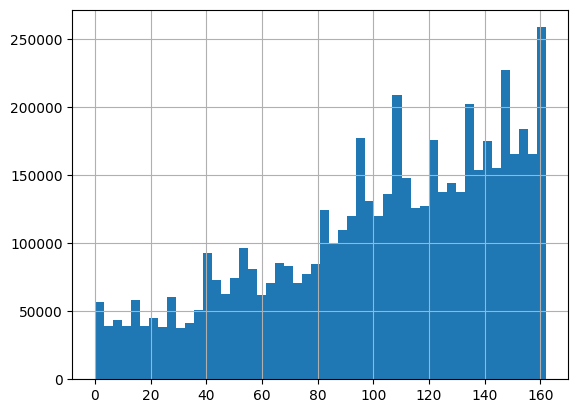

In [8]:
df['last_watch_dt'].hist(bins=50)

In [9]:
max_watch_dt = df['last_watch_dt'].max()
max_watch_dt

162

#### Разобьем датасет на трейн и тест. в тест отправим все события за последние 30 дней, в трейн все остальное. Посчитаем число уникальных юзеров в трейне и тесте, и юзеров, которые есть и там и там. Затем оставим в тесте только тех юзеров/айтемы, которые есть в трейне

In [10]:
threshold = max_watch_dt - 30

train_df = df[df['last_watch_dt'] < threshold].copy()
test_df  = df[df['last_watch_dt'] >= threshold].copy()

assert train_df.shape[0] == 3740952
assert test_df.shape[0] == 1735299

In [11]:
old_shape = test_df.shape[0]

train_users = train_df['user_id'].unique()
train_items = train_df['item_id'].unique()

test_df = test_df[test_df['user_id'].isin(train_users)]
test_df = test_df[test_df['item_id'].isin(train_items)]

assert test_df.shape[0] == 851974
assert test_df['user_id'].nunique() == 186701
assert test_df['item_id'].nunique() == 8867


print(f"Размер тестовой выборки после фильтрации: {test_df.shape[0]} (было удалено {old_shape - test_df.shape[0]} строк или {100 * (old_shape - test_df.shape[0]) / old_shape:.2f}%)")
print(f"Число уникальных пользователей в тестовой выборке: {test_df.user_id.nunique()}")

Размер тестовой выборки после фильтрации: 851974 (было удалено 883325 строк или 50.90%)
Число уникальных пользователей в тестовой выборке: 186701


#### Насэмплируем 50_000 юзеров которые есть и в трейне и в тесте и ограничим тестовую и трейновую выборку только этими пользователями

In [12]:
np.random.seed(42)
train_users = train_df['user_id'].unique()
test_users = test_df.user_id.unique()
n_users = 50_000

common_users = np.intersect1d(train_users, test_users)
sampled_users = np.random.choice(common_users, size=n_users, replace=False)

train_df = train_df[train_df['user_id'].isin(sampled_users)].copy()
test_df  = test_df [test_df ['user_id'].isin(sampled_users)].copy()

assert train_df['last_watch_dt'].max() < test_df['last_watch_dt'].min()
assert train_df['user_id'].nunique() == n_users
assert test_df['user_id'].nunique() == n_users

In [13]:
train_items = train_df['item_id'].unique()
test_df = test_df[test_df['item_id'].isin(train_items)].copy()

In [14]:
print(train_df['user_id'].nunique(), train_df['item_id'].nunique())
print(test_df['user_id'].nunique(), test_df['item_id'].nunique())
print(train_df.shape, test_df.shape)

50000 9743
49959 6159
(481529, 5) (227262, 5)


In [15]:
def ndcg_metric(gt_items, predicted):
    at = len(predicted)
    relevance = np.array([1 if x in predicted else 0 for x in gt_items])
    # DCG uses the relevance of the recommended items
    rank_dcg = dcg(relevance)

    if rank_dcg == 0.0:
        return 0.0

    # IDCG has all relevances to 1 (or the values provided), up to the number of items in the test set that can fit in the list length
    ideal_dcg = dcg(np.sort(relevance)[::-1][:at])

    if ideal_dcg == 0.0:
        return 0.0

    ndcg_ = rank_dcg / ideal_dcg

    return ndcg_


def dcg(scores):
    return np.sum(
        np.divide(np.power(2, scores) - 1, np.log2(np.arange(scores.shape[0], dtype=np.float64) + 2)), dtype=np.float64
    )


def recall_metric(gt_items, predicted):

    n_gt = len(gt_items)
    intersection = len(set(gt_items).intersection(set(predicted)))
    return intersection / n_gt


def evaluate_recommender(df, model_preds, gt_col="test_interactions", topn=10):
    metric_values = []

    for idx, row in df.iterrows():
        gt_items = row[gt_col]
        metric_values.append((ndcg_metric(gt_items, row[model_preds]), recall_metric(gt_items, row[model_preds])))

    return {"ndcg": np.mean([x[0] for x in metric_values]), "recall": np.mean([x[1] for x in metric_values])}

In [16]:
test_df_grouped = test_df.groupby('user_id').apply(lambda x: list(x['item_id']), include_groups=False).reset_index(name='test_interactions')
test_df_grouped.head()

,user_id,test_interactions
0,3,"[12192, 9728, 16406, 15719, 10440, 3475, 2025,..."
1,53,"[1445, 4151, 12250, 15629, 3734, 16426, 15810,..."
2,98,"[4689, 512, 5051]"
3,106,"[14619, 12908, 10544, 13335, 6267, 13463, 5411..."
4,155,"[8101, 5077, 281, 9006]"


### ALS

Итак, поставлена задача построения модели со скрытыми переменными (latent factor model) для коллаборативной фильтрации:

$$\sum_{u,i} (r_{ui} - \langle p_u, q_i \rangle)^2 \to \min_{P,Q}. $$

Напомним, что суммирование ведется по всем парам $(u, i),$ для которых известен рейтинг $r_{ui}$ (и только по ним), а $p_u, q_i$ – латентные представления пользователя $u$ и товара $i$ из соответствующих матрицы $P, Q$.

Подход ALS (Alternating Least Squares) решает задачу, попеременно фиксируя матрицы $P$ и $Q$, — оказывается, что, зафиксировав одну из матриц, можно выписать аналитическое решение задачи для другой.

$$\nabla_{p_u} \bigg[ \sum_{u,i} (r_{ui} - \langle p_u, q_i \rangle)^2 \bigg] = \sum_{i} 2(r_{ui} - \langle p_u, q_i \rangle)q_i = 0$$

Воспользовавшись тем, что $a^Tbc = cb^Ta$, получим
$$\sum_{i} r_{ui}q_i - \sum_i q_i q_i^T p_u = 0.$$
Тогда окончательно каждый столбец матрицы $P$ можно найти по формуле
$$p_u = \bigg( \sum_i q_i q_i^T\bigg)^{-1}\sum_ir_{ui}q_i \;\; \forall u,$$
аналогично для столбцов матрицы $Q$
$$q_i = \bigg( \sum_u p_u p_u^T\bigg)^{-1}\sum_ur_{ui}p_u \;\; \forall i.$$

Таким образом мы можем решать оптимизационную задачу, поочередно фиксируя одну из матриц $P$ или $Q$ и проводя оптимизацию по второй.

**Оригинальная статья (для explicit feedback):**

Bell, R.M. and Koren, Y., 2007, October. Scalable collaborative filtering with jointly derived neighborhood interpolation weights. In Seventh IEEE international conference on data mining (ICDM 2007) (pp. 43-52). IEEE.


### iALS


**Статья для implicit данных:**


Implicit feedback ALS:
* Hu, Y., Koren, Y. and Volinsky, C., 2008, December. Collaborative filtering for implicit feedback datasets. In 2008 Eighth IEEE international conference on data mining (pp. 263-272). Ieee. http://yifanhu.net/PUB/cf.pdf

**Особенности:**

1. Нет explicit данных (явных позитивных и отрицательных оценок). <br>
2. Много шума в данных.  <br>
3. Используются свои функции и метрики для оценки implicit feedback. Если в explicit $r_ui$ - это оценки предпочтений пользователя, то в implicit - это степень уверенности. <br>


| Критерий | ALS  |  iALS |
|---|---|---|
| Тип данных | Этот подход используется, когда у вас есть явные рейтинги или оценки, предоставленные пользователями для различных предметов. Например, пользователи могут оценивать фильмы по шкале от 1 до 5. |  Этот подход используется, когда у вас есть неявные сигналы взаимодействия между пользователями и предметами, такие как клики, просмотры, покупки или временные интервалы между действиями. |  
|
|Цель | Модель стремится точно предсказать явные рейтинги или оценки, которые пользователи могли бы дать предметам. | Модель стремится моделировать уровень уверенности или важности взаимодействия между пользователем и предметом, но не предсказывает явные рейтинги.|  
|
|Функции потерь| Обычно использует функцию потерь, такую как среднеквадратичная ошибка (MSE), для минимизации разницы между предсказанными и фактическими оценками. | Использует функцию потерь, которая учитывает уверенность в неявных взаимодействиях и стремится увеличить уверенность для более важных взаимодействий.|
|
|Взвешивание| Не уделяет внимания взаимодействиям, которые не были явно оценены пользователями. Исключает информацию о неявных действиях. | Дополнительная параметризация. Учитывает все неявные действия, но с учетом их уверенности или веса, что позволяет модели учесть важность различных видов взаимодействий|
|

Библиотека implicit: https://benfred.github.io/implicit/

In [17]:
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import LabelEncoder
from tqdm.auto import tqdm
from scipy.sparse import csr_matrix

class NaiveALS:
    def __init__(self, n_iters, n_factors, reg=0):
        self.reg = reg
        self.n_iters = n_iters
        self.n_factors = n_factors

    def fit(self, train, test):
        n_users = train["user_id"].nunique()
        m_items = train["item_id"].nunique()

        self.user_encoder = LabelEncoder()
        self.item_encoder = LabelEncoder()

        encoded_users = self.user_encoder.fit_transform(train["user_id"].values)
        encoded_item  = self.item_encoder.fit_transform(train["item_id"].values)

        train_ratings = np.zeros((n_users, m_items), dtype=np.float32)
        train_ratings[encoded_users, encoded_item] = 1.0

        self.train_ratings = train_ratings
        self.train_R = csr_matrix(train_ratings)

        self.P = np.random.rand(n_users, self.n_factors).astype(np.float32)
        self.Q = np.random.rand(m_items, self.n_factors).astype(np.float32)

        for i in tqdm(range(self.n_iters)):
            self.P = self._als_step(self.train_R,       self.P, self.Q, n_solve=n_users, n_fixed=m_items)
            self.Q = self._als_step(self.train_R.T.tocsr(), self.Q, self.P, n_solve=m_items, n_fixed=n_users)

    def _als_step(self, R, solve_vecs, fixed_vecs, n_solve, n_fixed):
        k = fixed_vecs.shape[1]
        reg_eye = self.reg * np.eye(k, dtype=fixed_vecs.dtype)

        result = np.zeros((n_solve, k), dtype=fixed_vecs.dtype)

        for u in range(n_solve):
            start, end = R.indptr[u], R.indptr[u + 1]
            idx = R.indices[start:end]
            if len(idx) == 0:
                continue
            Q_u = fixed_vecs[idx]
            A_u = Q_u.T @ Q_u + reg_eye
            b_u = Q_u.sum(axis=0)
            result[u] = np.linalg.solve(A_u, b_u)

        return result


    def predict(self):
        pred = self.P.dot(self.Q.T)
        return pred

    def get_top_k_predicts(self, k: int, batch_size: int = 2000):
        n_users, m_items = self.P.shape[0], self.Q.shape[0]
        k = min(k, m_items - 1)

        out_recs = []
        out_users = []

        for start in range(0, n_users, batch_size):
            end = min(start + batch_size, n_users)
            P_batch = self.P[start:end]
            scores = P_batch @ self.Q.T

            # маскируем просмотренные
            R_batch = self.train_R[start:end]
            for j in range(scores.shape[0]):
                lo, hi = R_batch.indptr[j], R_batch.indptr[j + 1]
                scores[j, R_batch.indices[lo:hi]] = -np.inf

            top_idx = np.argpartition(-scores, k - 1, axis=1)[:, :k]
            rows = np.arange(scores.shape[0])[:, None]
            order = np.argsort(-scores[rows, top_idx], axis=1)
            top_idx = top_idx[rows, order]

            out_recs.append(top_idx)
            out_users.append(np.arange(start, end))

        top_idx_all = np.vstack(out_recs)
        users_idx_all = np.concatenate(out_users)

        users_orig = self.user_encoder.inverse_transform(users_idx_all)
        df_pred = pd.DataFrame({
            'user_id': users_orig,
            'naive_als_pred': [self.item_encoder.inverse_transform(row).tolist()
                              for row in top_idx_all],
        })
        return df_pred

    @staticmethod
    def compute_mse(y_true, y_pred):
        mask = np.nonzero(y_true)
        mse = mean_squared_error(y_true[mask], y_pred[mask])
        return mse

In [18]:
naive_als = NaiveALS(n_iters=10, n_factors=16, reg=0.01)
naive_als.fit(train_df, test_df)

  0%|          | 0/10 [00:00<?, ?it/s]

In [19]:
preds = naive_als.get_top_k_predicts(k=50)
test_df_grouped["als_recs_naive"] = preds['naive_als_pred']
evaluate_recommender(test_df_grouped, model_preds="als_recs_naive")

{'ndcg': np.float64(0.24014816883443493),
 'recall': np.float64(0.14991531883118042)}

In [20]:
from typing import List

from scipy.sparse import csr_matrix
from implicit.als import AlternatingLeastSquares
from implicit.bpr import BayesianPersonalizedRanking

from sklearn.metrics import mean_squared_error


class ImplicitModel:
    def __init__(self, model):
        self.model = model
        self.trained = False

    def fit(self, train_df: pd.DataFrame):
        self.item_encoder = LabelEncoder()
        self.user_encoder = LabelEncoder()
        self.item_encoder.fit(train_df.item_id)
        self.user_encoder.fit(train_df.user_id)

        self.train_ratings = self.encode_table(train_df, ["user_id", "item_id"])
        self.model.fit(self.train_ratings)
        self.trained = True

    def predict(self, test_df: pd.DataFrame, top_k: int = 100):
        if not self.trained:
            raise ValueError("Model is not fitted. Please, fit the model first")
        users_to_predict = test_df.user_id
        encoded_users = self.user_encoder.transform(users_to_predict)
        user_recs = self.model.recommend(
            encoded_users, self.train_ratings[encoded_users], N=top_k, filter_already_liked_items=True
        )[0]
        recs = [self.item_encoder.inverse_transform(x) for x in user_recs]
        return recs

    def encode_table(self, df: pd.DataFrame, axis_names: List[str]) -> np.ndarray:
        user_ids = self.user_encoder.transform(df[axis_names[0]])
        item_ids = self.item_encoder.transform(df[axis_names[1]])

        matrix_shape = len(self.user_encoder.classes_), len(self.item_encoder.classes_)

        sparse = csr_matrix((np.ones(len(user_ids)), (user_ids, item_ids)), shape=matrix_shape, dtype=np.float32)

        return sparse

In [21]:
als = AlternatingLeastSquares(iterations=10, factors=16, regularization=0.01, calculate_training_loss=True)
als_recommender = ImplicitModel(als)
als_recommender.fit(train_df)

/usr/local/lib/python3.13/dist-packages/implicit/cpu/als.py:96: RuntimeWarning: OpenBLAS is configured to use 2 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


  0%|          | 0/10 [00:00<?, ?it/s]

In [22]:
preds = als_recommender.predict(test_df_grouped, top_k=50)
test_df_grouped["als_recs"] = preds
evaluate_recommender(test_df_grouped, model_preds="als_recs")

{'ndcg': np.float64(0.32799159883516366),
 'recall': np.float64(0.21068387541693856)}

In [23]:
user_encoder = LabelEncoder().fit(train_df["user_id"])
item_encoder = LabelEncoder().fit(train_df["item_id"])

In [24]:
import torch
import torch.nn as nn

In [25]:
train_encoded_users = torch.Tensor(user_encoder.transform(train_df["user_id"].values)).long()
train_encoded_items = torch.Tensor(item_encoder.transform(train_df["item_id"].values)).long()

In [26]:
user_encoder = LabelEncoder().fit(train_df["user_id"])
item_encoder = LabelEncoder().fit(train_df["item_id"])

In [28]:
def transform(x):
    encoded = item_encoder.transform(x)
    return encoded.tolist()

In [29]:
user_interactions = train_df.groupby(["user_id"]).agg({"item_id": transform})
user_interactions

,item_id
user_id,
3,"[2200, 1548]"
53,"[914, 9506, 8183, 960, 4463, 9057, 3904, 6191,..."
98,"[2672, 74, 1407, 977, 1210, 4889, 2932, 2819, ..."
106,"[1852, 5577, 164, 2803, 4024, 2112, 1487, 9537..."
155,"[8209, 215, 2791, 5413]"
...,...
1097470,"[5401, 2662, 8734, 1131, 4857, 9353, 8522, 518..."
1097474,"[2004, 8405]"
1097479,"[5413, 2200, 2819, 6331, 2393]"


In [34]:
class NCF(torch.nn.Module):
    def __init__(self, n_users: int, m_items: int, n_factors: int, hidden_dim: int) -> None:
        super().__init__()
        self.n_users = n_users
        self.m_items = m_items
        self.n_factors = n_factors
        self.hidden_dim = hidden_dim

        # GMF часть
        self.user_emb = nn.Embedding(n_users, n_factors)
        self.item_emb = nn.Embedding(m_items, n_factors)

        # MLP часть
        self.mlp = nn.Sequential(
            nn.Linear(2 * n_factors, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, 1),
        )

        nn.init.normal_(self.user_emb.weight, std=0.01)
        nn.init.normal_(self.item_emb.weight, std=0.01)

    def forward(self, item, user) -> torch.tensor:
        u = self.user_emb(user)
        i = self.item_emb(item)

        # GMF
        gmf = u * i

        # MLP
        mlp_in = torch.cat([u, i], dim=-1)
        mlp_out = self.mlp(mlp_in)

        logits = gmf.sum(dim=-1, keepdim=True) + mlp_out
        prediction = torch.sigmoid(logits)

        return prediction

In [35]:
ncf_model = NCF(n_users=len(user_encoder.classes_), m_items=len(item_encoder.classes_), n_factors=16, hidden_dim=64)
ncf_model

NCF(
  (user_emb): Embedding(50000, 16)
  (item_emb): Embedding(9743, 16)
  (mlp): Sequential(
    (0): Linear(in_features=32, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)

In [36]:
optimizer = torch.optim.SGD(ncf_model.parameters(), lr=1e-4)
loss = nn.BCELoss()

all_items = set(list(range(ncf_model.m_items)))

for user, item in tqdm(zip(train_encoded_users, train_encoded_items), total=len(train_encoded_users)):
    optimizer.zero_grad()
    # сэмплируем негативы для пользователя из айтемов, с которыми он не взаимодействовал
    seen_items = set(user_interactions.loc[user_encoder.inverse_transform([user.item()])])
    unseen_items = list(all_items - seen_items)
    neg_item = torch.Tensor(np.array([np.random.choice(unseen_items, size=1)])).long()[0][0]

    # считаем скор позитивного взаимодействия
    pos_prediction = ncf_model(item, user)
    # считаем скор негативного взаимодействия
    neg_prediction = ncf_model(neg_item, user)

    # лосс для каждого из типов взаимодействий
    cur_loss = loss(pos_prediction, torch.Tensor([1]).float())
    cur_loss += loss(neg_prediction, torch.Tensor([0]).float())

    cur_loss.backward()
    optimizer.step()

  0%|          | 0/481529 [00:00<?, ?it/s]

#### Реализовать инференс модели и подсчет метрик

In [37]:
@torch.no_grad()
def ncf_recommend(model, user_encoder, item_encoder, users, top_k=50, batch_size=512):
    model.eval()
    device = next(model.parameters()).device

    all_item_ids = torch.arange(model.m_items, device=device)
    user_enc = user_encoder.transform(users)
    user_enc_t = torch.tensor(user_enc, dtype=torch.long, device=device)

    recs = []
    for start in range(0, len(user_enc_t), batch_size):
        batch_users = user_enc_t[start:start + batch_size]
        B = batch_users.size(0)

        # разворачиваем всех айтемов для каждого юзера
        users_exp = batch_users.unsqueeze(1).expand(B, model.m_items).reshape(-1)
        items_exp = all_item_ids.unsqueeze(0).expand(B, model.m_items).reshape(-1)

        scores = model(items_exp, users_exp).view(B, model.m_items)

        # маскируем уже просмотренные
        for j, u in enumerate(batch_users.cpu().numpy()):
            orig_user = user_encoder.inverse_transform([u])[0]
            seen = train_df.loc[train_df['user_id'] == orig_user, 'item_id'].unique()
            if len(seen):
                seen_enc = item_encoder.transform(seen)
                scores[j, seen_enc] = -np.inf

        k = min(top_k, scores.size(1))
        top_idx = torch.topk(scores, k=k, dim=1).indices.cpu().numpy()
        recs.extend([item_encoder.inverse_transform(row).tolist() for row in top_idx])

    return recs

In [38]:
users_test = test_df_grouped['user_id'].values
ncf_recs = ncf_recommend(
    ncf_model, user_encoder, item_encoder, users_test, top_k=50, batch_size=256
)
test_df_grouped['ncf_recs'] = ncf_recs

print("NCF:", evaluate_recommender(test_df_grouped, model_preds="ncf_recs"))
print("ALS:", evaluate_recommender(test_df_grouped, model_preds="als_recs"))

NCF: {'ndcg': np.float64(0.20111759099280918), 'recall': np.float64(0.12547689478166088)}
ALS: {'ndcg': np.float64(0.32799159883516366), 'recall': np.float64(0.21068387541693856)}
